# VNET SUPERVISED

In [ ]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import json
from pprint import pprint
from os import listdir
import datetime
from pathlib import Path
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader

np.set_printoptions(precision=2,suppress=True,linewidth=50000)
os.chdir(r"C:\Users\Bea Loubser\OneDrive\Desktop\Thesis\Vnet_seaturtles_semisupervised\notebooks")

print(os.getcwd())

torch.__version__
torch.xpu.is_available()

C:\Users\Bea Loubser\OneDrive\Desktop\Thesis\Vnet_seaturtles_semisupervised\notebooks


In [8]:
""" a dictionary to store all the information """
memo=pd.Series()

In [9]:
"""
functions
"""
def load_dico(path,key_int=False,print_me=False):
    with open(path) as f:
        dico_str = json.loads(json.load(f))

    if key_int:
        conv_key=lambda k:int(k)
    else:
        conv_key=lambda k:k

    dico={conv_key(k):v for k,v in dico_str.items()}

    if print_me:
        print(dico)

    return dico



def value_count(vec):

    value,count=np.unique(vec,return_counts=True)
    count_sort_ind = np.argsort(-count)
    value_sort=value[count_sort_ind]

    return value_sort,-np.sort(-count)


class classCLASS:

    def __init__(self,id,name,behaviors,score_weight,sampling_weight=1,loss_weight=1):
        self.id=id
        self.name=name
        self.behaviors=behaviors
        self.score_weight=score_weight
        self.sampling_weight=sampling_weight
        self.loss_weight=loss_weight

## Parameters


In [10]:
CASE=memo["CASE"]="TestA_pressurecorrected" #give a different name if change parameter

#the Behavioral categories defined by classCLASS : id ,name of behavior ,behaviors number in the data csv, score_weight to calculate accuracy,sampling_weight=1,loss_weight=1
Other=classCLASS(0,"Other",None,0,1,0.1)
Breathing=classCLASS(1,"Breathing",[1,2,40],1)
Feeding=classCLASS(2,"Feeding",[3,4,5,6,7,11,12,13,18,19,20,21],10,2,2)
Gliding=classCLASS(3,"Gliding",[16,17],1,3)
Resting=classCLASS(4,"Resting",[29,30,31,32],1,0.5)
Scratching=classCLASS(5,"Scratching",[34,35,36],2,2,2)
Swimming=classCLASS(6,"Swimming",[42,45,48,43,46,49,27,44,47,50,56,52,54,55],1,0.5)

CLASSES=[Other,Breathing,Feeding,Gliding,Resting,Scratching,Swimming]

DESCRIPTORS_SELEC=[1,2,3,4,5,6,25] #the variables that are going to be used to train the Vnet
WINDOW_DURA=40 #size of the window in seconds
RESAMPLING_STEP_S=0.0500 #freq of the csv files
DIR_IN="Data/out_A_09062025"  # where to find the data

WINDOW_SIZE=int(WINDOW_DURA/RESAMPLING_STEP_S) #size of the window and therefore input
COL_BEH=27


#Parameters of the Vnet
LR_initial=0.0001
BATCH_SIZE=32
MODEL_DEPTH=32
MODEL_HEAD="softmax"
DROPOUT=0.5

In [ ]:
#Training?validation/testing dataset

NAMES_TRAIN=memo["NAMES_TRAIN"]=[
                     'CC-07-48_18-02-2019',#10
                     'CC-07-48_06-10-2018',#6
                     'CC-07-48_04-10-2018',#5
                     'CC-07-115_13-05-2019',#3
                     'CC-07-115_14-05-2019',#3
                     'CC-07-48_08-04-2019_1', #7
                     'CC-07-48_08-04-2019_2', #7
                     'CC-07-48_08-04-2019_3', #7
                     'CC-07-48_22-05-2018', #121
                      'CC-07-108_11-02-2019', #

                    ]

NAMES_VAL=memo["NAMES_VAL"]=[
    'CC-07-59_20-05-2018', #13
    'CC-07-47_14-02-2018', #4
    'CC-07-48_10-10-2018'#9
    ]


NAMES_TEST=memo["NAMES_TEST"]=[
    'CC-07-48_08-10-2018',#8
    'CC-07-48_26-05-2018',#12
    'CC-07-107_11-02-2019' #1
    ]

NAMES_ALL=NAMES_TRAIN+NAMES_VAL+NAMES_TEST

In [12]:
print("Training split: ",len(NAMES_TRAIN)/len(NAMES_ALL)*100,"%")
print("Validation split: ",len(NAMES_VAL)/len(NAMES_ALL)*100,"%")
print("Testing split: ",len(NAMES_TEST)/len(NAMES_ALL)*100,"%")

Training split:  62.5 %
Validation split:  18.75 %
Testing split:  18.75 %


In [13]:
#save everyhting in dictionary
memo["MODEL_HEAD"]=MODEL_HEAD

memo["MODEL_DEPTH"]=MODEL_DEPTH

memo["BATCH_SIZE"]=BATCH_SIZE
memo["LR_initial"]=LR_initial
memo["WINDOW_DURA"]=WINDOW_DURA

memo["DIR_IN"]=DIR_IN
memo["RESAMPLING_STEP_S"]=RESAMPLING_STEP_S
for CLASS in CLASSES:
    memo["CLASSES_"+CLASS.name]=CLASS.__dict__
memo["DROPOUT"]=DROPOUT
memo["DESCRIPTORS_SELEC"]=DESCRIPTORS_SELEC

### Create folder to save results

In [14]:
now = datetime.datetime.now()
today=now.strftime("%Y_%m_%d")
today

'2026_08_14'

In [15]:
DIR_OUT="Model_results/modelVNET="+today+"_"+CASE
DIR_OUT

'Model_results/modelVNET=2026_08_14_TestA_pressurecorrected'

In [16]:
# "DANGER: THIS CLEAR ALL THE SAVED WORK (except if the CASE or the day change)"

import shutil
if os.path.exists(DIR_OUT):
    shutil.rmtree(DIR_OUT)
    print("we clear the directory:",DIR_OUT)
else:
    print("we create the directory:",DIR_OUT)

"""création des dossiers """
os.makedirs(DIR_OUT)

we create the directory: Model_results/modelVNET=2026_08_14_TestA_pressurecorrected


## Load the data

In [17]:
dico_info_A=load_dico(DIR_IN+ "/dico_info.json",print_me=True);
#behName_to_behInd=load_dico(DIR_IN+"/behName_to_behInd.json",print_me=True);
#behInd_to_behName=load_dico(DIR_IN+"/behInd_to_behName.json",key_int=True,print_me=True);

{'RESAMPLING_STEP_S': 0.05, 'col_names': ['index', 'Accelerometer X [m/s²]', 'Accelerometer Y [m/s²]', 'Accelerometer Z [m/s²]', 'Gyroscope X [mrad/s]', 'Gyroscope Y [mrad/s]', 'Gyroscope Z [mrad/s]', 'Magnetometer X [µT]', 'Magnetometer Y [µT]', 'Magnetometer Z [µT]', 'Depth [m]', 'Light intensity 1 [raw]', 'Temperature (imu) [°C]', 'StX', 'StY', 'StZ', 'DX', 'DY', 'DZ', 'dba', 'AccX_high', 'AccY_high', 'AccZ_high', 'Pressure_corr', 'Pressure_diff_1s', 'Pressure_diff_2s', 'Pressure_diff_3s', 'beh']}


In [18]:
##check whcih variables we are going to use
DESC_NAMES=dico_info_A['col_names']
DESC_NAMES_SELEC=[]
for i,name in enumerate(DESC_NAMES):
    if i in DESCRIPTORS_SELEC:
        prefix=""
        DESC_NAMES_SELEC.append(name)
    else:
        prefix="-----suppressed----->"
    print(prefix,i,name)

-----suppressed-----> 0 index
 1 Accelerometer X [m/s²]
 2 Accelerometer Y [m/s²]
 3 Accelerometer Z [m/s²]
 4 Gyroscope X [mrad/s]
 5 Gyroscope Y [mrad/s]
 6 Gyroscope Z [mrad/s]
-----suppressed-----> 7 Magnetometer X [µT]
-----suppressed-----> 8 Magnetometer Y [µT]
-----suppressed-----> 9 Magnetometer Z [µT]
-----suppressed-----> 10 Depth [m]
-----suppressed-----> 11 Light intensity 1 [raw]
-----suppressed-----> 12 Temperature (imu) [°C]
-----suppressed-----> 13 StX
-----suppressed-----> 14 StY
-----suppressed-----> 15 StZ
-----suppressed-----> 16 DX
-----suppressed-----> 17 DY
-----suppressed-----> 18 DZ
-----suppressed-----> 19 dba
-----suppressed-----> 20 AccX_high
-----suppressed-----> 21 AccY_high
-----suppressed-----> 22 AccZ_high
-----suppressed-----> 23 Pressure_corr
-----suppressed-----> 24 Pressure_diff_1s
 25 Pressure_diff_2s
-----suppressed-----> 26 Pressure_diff_3s
-----suppressed-----> 27 beh


In [19]:
def load_mat(names):
    matrices={}
    labels={}

    for name in names:
        full_name=DIR_IN+"/"+name+".npy"
        if not os.path.exists(full_name):
            assert 1==0,"the file:"+full_name+" cannot be found"
        else:
            full_mat=np.load(full_name)
            pre_label=full_mat[:,COL_BEH]

            label=np.zeros_like(pre_label)
            for CLASS in CLASSES:
                if CLASS!=Other:
                    for beh in CLASS.behaviors:
                        label[pre_label==beh]=CLASS.id


            #np.save(DIR_OUT+"/"+name+"=pre_label",pre_label)
            mat=full_mat[:,DESCRIPTORS_SELEC]
            print("loading the matrix:"+name)
            print("shape:",mat.shape)
            print("duration in seconds:",len(mat)*RESAMPLING_STEP_S)
            print("duration in hour:",round(len(mat)*RESAMPLING_STEP_S/60/60,2))
            print()
            matrices[name]=mat
            labels[name]=label

    return matrices,labels

    print("number of loaded matrices:",len(matrices))

In [20]:
matrices,labels=load_mat(NAMES_ALL)

loading the matrix:CC-07-48_18-02-2019
shape: (559219, 7)
duration in seconds: 27960.95
duration in hour: 7.77

loading the matrix:CC-07-48_06-10-2018
shape: (475183, 7)
duration in seconds: 23759.15
duration in hour: 6.6

loading the matrix:CC-07-48_04-10-2018
shape: (284021, 7)
duration in seconds: 14201.050000000001
duration in hour: 3.94

loading the matrix:CC-07-115_13-05-2019
shape: (731266, 7)
duration in seconds: 36563.3
duration in hour: 10.16

loading the matrix:CC-07-115_14-05-2019
shape: (325009, 7)
duration in seconds: 16250.45
duration in hour: 4.51

loading the matrix:CC-07-48_08-04-2019_1
shape: (157315, 7)
duration in seconds: 7865.75
duration in hour: 2.18

loading the matrix:CC-07-48_08-04-2019_2
shape: (88800, 7)
duration in seconds: 4440.0
duration in hour: 1.23

loading the matrix:CC-07-48_08-04-2019_3
shape: (142801, 7)
duration in seconds: 7140.05
duration in hour: 1.98

loading the matrix:CC-07-48_22-05-2018
shape: (286161, 7)
duration in seconds: 14308.0500000

In [21]:
print("Training dataset")
for name in NAMES_TRAIN:
    print(name,matrices[name].shape)
print("Validation dataset")
for name in NAMES_VAL:
    print(name,matrices[name].shape)

Training dataset
CC-07-48_18-02-2019 (559219, 7)
CC-07-48_06-10-2018 (475183, 7)
CC-07-48_04-10-2018 (284021, 7)
CC-07-115_13-05-2019 (731266, 7)
CC-07-115_14-05-2019 (325009, 7)
CC-07-48_08-04-2019_1 (157315, 7)
CC-07-48_08-04-2019_2 (88800, 7)
CC-07-48_08-04-2019_3 (142801, 7)
CC-07-48_22-05-2018 (286161, 7)
CC-07-108_11-02-2019 (160292, 7)
Validation dataset
CC-07-59_20-05-2018 (423855, 7)
CC-07-47_14-02-2018 (105362, 7)
CC-07-48_10-10-2018 (69239, 7)


## Visualization


In [22]:
def histoOneTortue(matrix):
    nb_col=matrix.shape[1]
    cols = 3
    rows = (nb_col + cols - 1) // cols
    fig,axs=plt.subplots(rows,cols,figsize=(cols*4,rows * 3))
    axs = axs.flatten()
    for j in range(nb_col):
        axs[j].hist(matrix[:,j],bins=40,edgecolor='k')
        axs[j].set_title(DESC_NAMES_SELEC[j], color="coral")
        axs[j].tick_params(colors='coral')
    plt.tight_layout()
    plt.show()

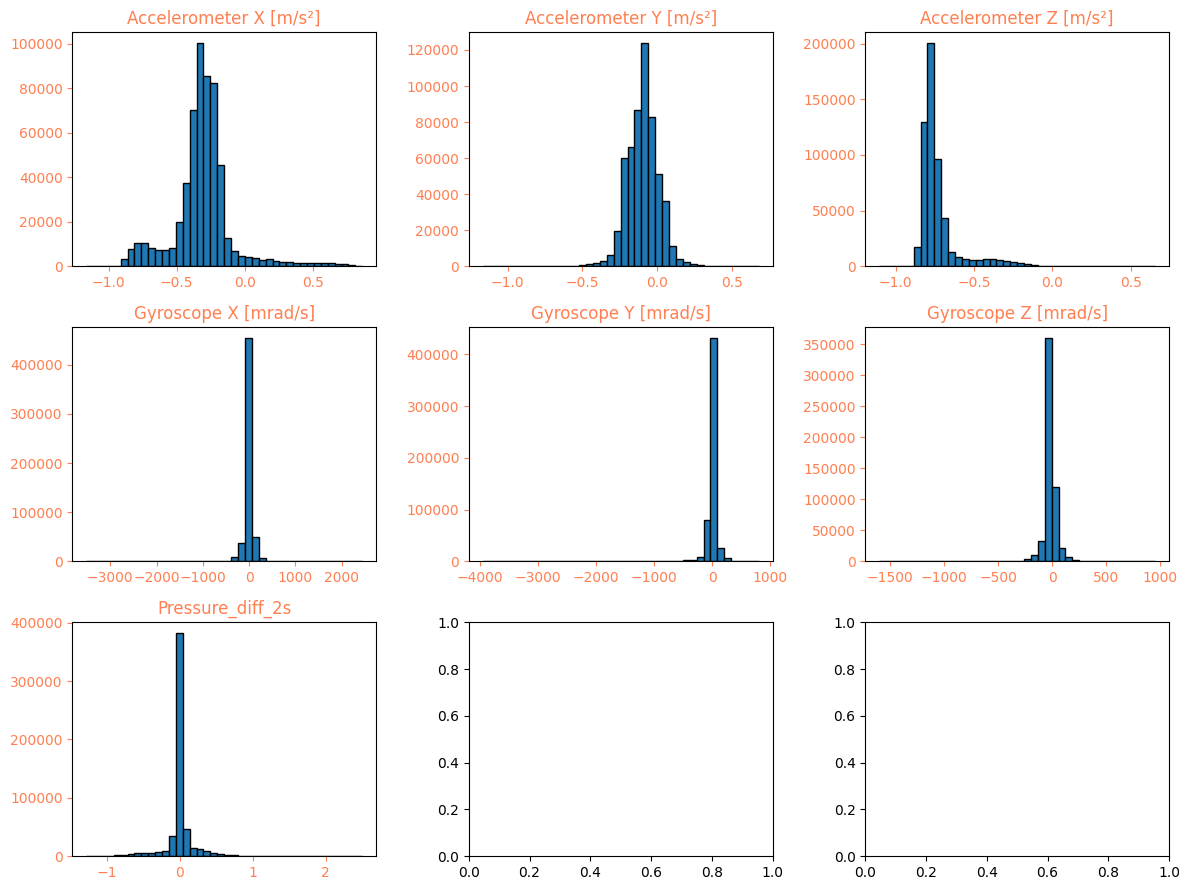

In [23]:
histoOneTortue(matrices[NAMES_TRAIN[0]])

In [24]:
def plotOneTortue(name,deb=0,fin=-1):

    matrix=matrices[name]
    label=labels[name]
    nb_col=matrix.shape[1]

    fig,axs=plt.subplots(nb_col+1,1,figsize=(12,(nb_col+1)*2))

    axs[0].plot(label[deb:fin])
    for i in range(nb_col):

        axs[i+1].plot(matrix[deb:fin,i])
        axs[i+1].set_title(DESC_NAMES_SELEC[i])

    title=name+"_"+str(deb)+"->"+str(fin)
    fig.suptitle(title)

    fig.tight_layout()


    #fig.savefig(DIR_OUT+"/"+title)

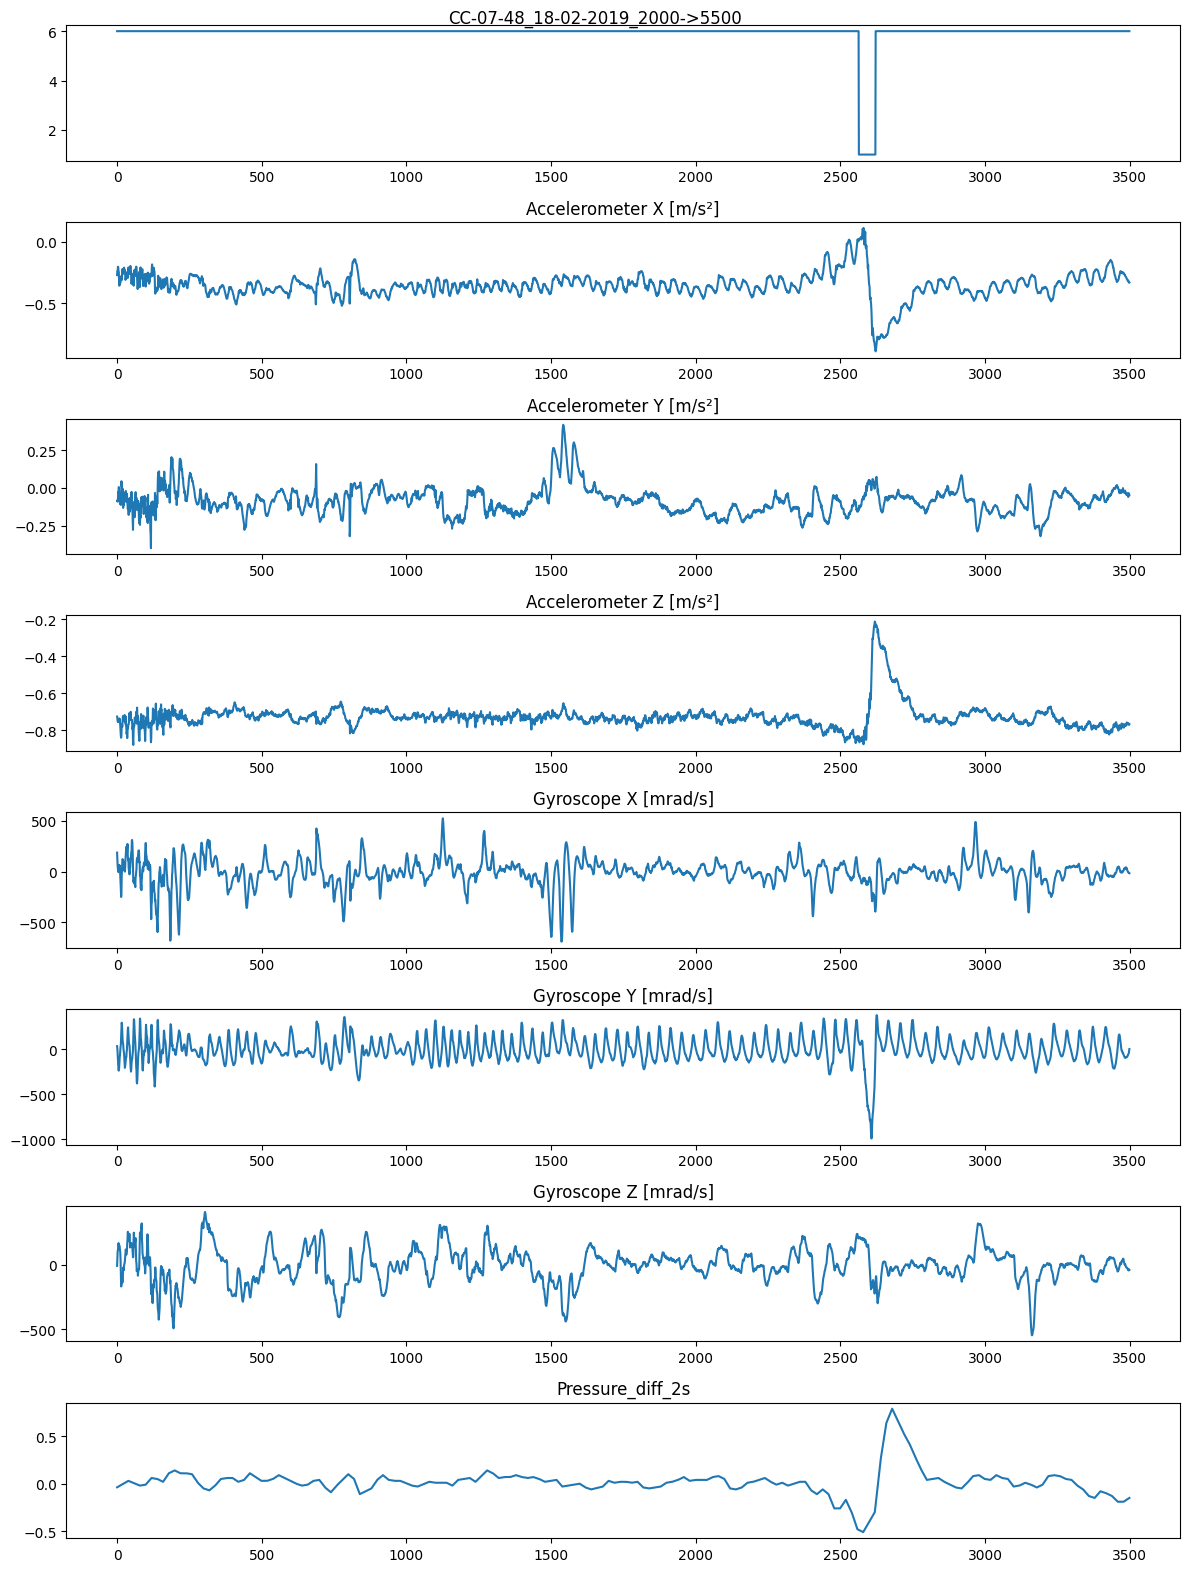

In [25]:
plotOneTortue(NAMES_TRAIN[0],2000,5500)

In [26]:
all_values=np.concatenate([v for v in matrices.values()])

In [27]:
all_values.shape

(4957167, 7)

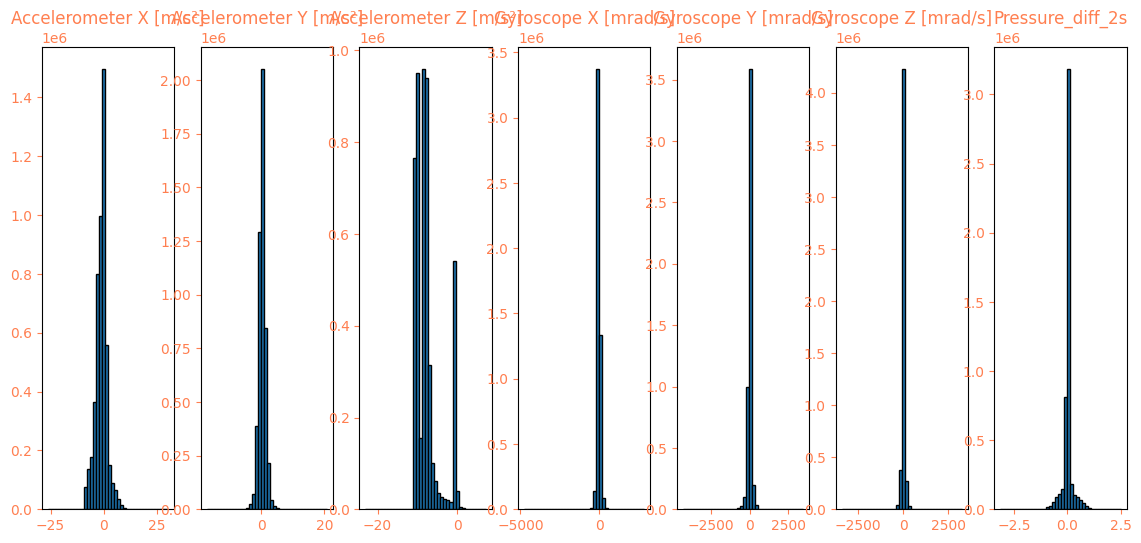

In [28]:
nb_col=all_values.shape[1]
fig,axs=plt.subplots(1,nb_col,figsize=(nb_col*2,6))
#axs=axs.flatten(nb_col)
for j in range(nb_col):
        axs[j].hist(all_values[:,j],bins=40,edgecolor='k')
        axs[j].set_title(DESC_NAMES_SELEC[j], color="coral")
        axs[j].tick_params(colors='coral')
plt.show()

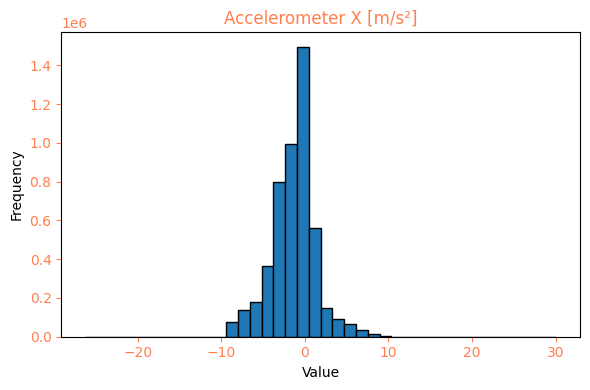

In [29]:
col_index = 0

plt.figure(figsize=(6, 4))  # Width=6 inches, Height=4 inches
plt.hist(all_values[:, col_index], bins=40, edgecolor='k')
plt.title(DESC_NAMES_SELEC[col_index], color="coral")
plt.tick_params(colors='coral')
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [30]:
from scipy.stats import normaltest
stat_dagostino, p_dagostino = normaltest(all_values[:, col_index])
print(f"  D’Agostino-Pearson: p = {p_dagostino:.4f} {'(normal)' if p_dagostino > 0.05 else '(not normal)'}\n")

  D’Agostino-Pearson: p = 0.0000 (not normal)



## Normalization of the data

In [31]:
def normalize():

    nb_col=matrices[NAMES_ALL[0]].shape[1]
    for matrix in matrices.values():
        for j in range(nb_col):
            matrix[:,j]-=matrix[:,j].mean()
            matrix[:,j]/=matrix[:,j].std()



In [32]:
normalize()

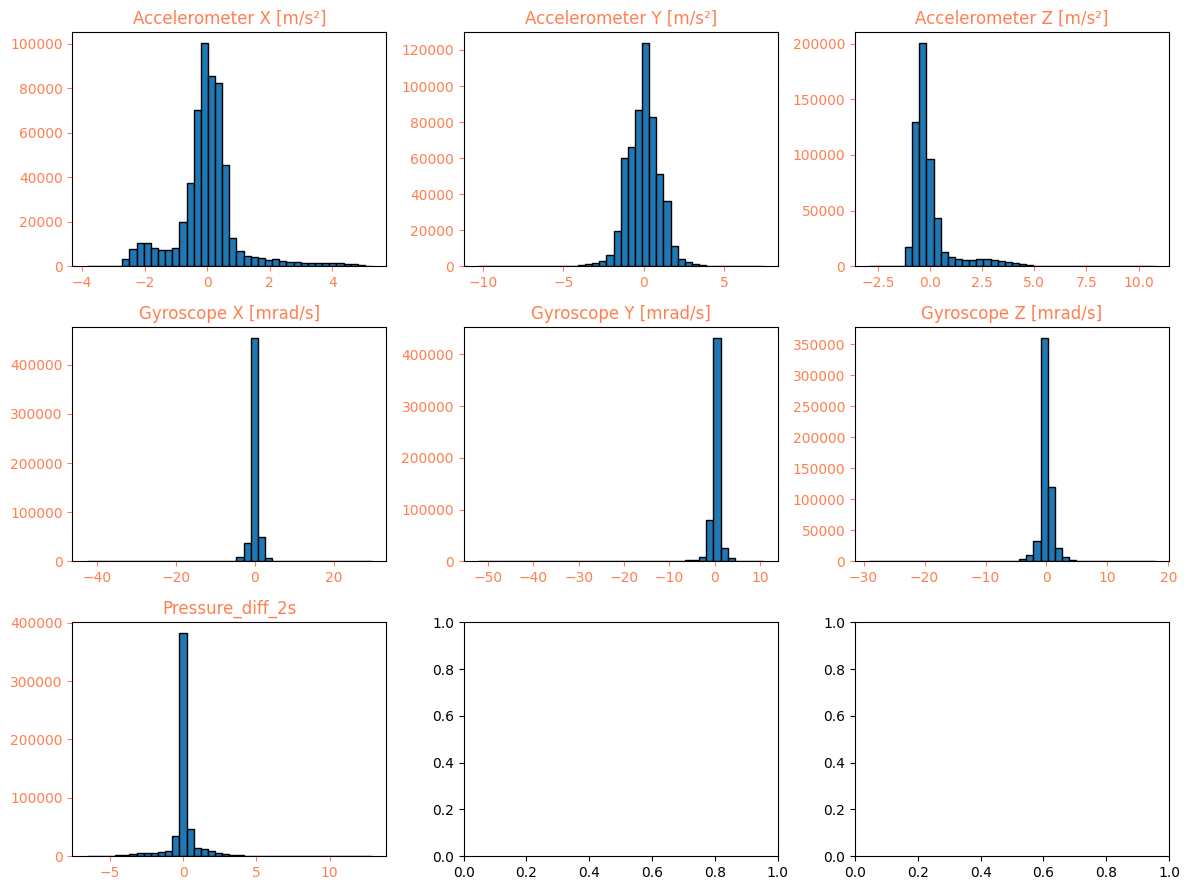

In [33]:
histoOneTortue(matrices[NAMES_TRAIN[0]])

# Data Generator

In [34]:
def density_for_one_promotion(turtle_name, CLASS):

    label=labels[turtle_name]

    N = len(label)
    dens = np.zeros_like(label)

    dens[label==CLASS.id] = 1

    sum_dens=np.sum(dens)
    if  sum_dens<1e-6:
        print("the class to promote:"+CLASS.name +" is not present in:"+turtle_name)
        dens[:]=1
        sum_dens=len(dens)


    dens/=sum_dens

    # creating a mask.
    kernel = np.ones(int(1.5*WINDOW_SIZE))#avant cela dépendait de N
    kernel/=np.sum(kernel)
    #gauss = np.exp(-t**2)
    #gauss /= np.sum(gauss)

    # convolving label with a mask
    dens_conv = np.convolve(dens, kernel, mode='same')#+min_dens

    dens_conv[-WINDOW_SIZE//2-2:]=0
    dens_conv[:WINDOW_SIZE//2+2]=0

    cdf=np.cumsum(dens_conv)
    cdf/=cdf[-1]

    def rand_gene():
        while True:
                yield np.argmax(cdf>np.random.random())-WINDOW_SIZE//2

    return dens,dens_conv,cdf,rand_gene()

In [35]:
class InterestingTurtles:

    def __init__(self,turtle_names,CLASS):
        self.turtle_names=turtle_names
        self.occurences=np.zeros(len(turtle_names))
        self.CLASS=CLASS

        for i,name in enumerate(turtle_names):
            self.occurences[i]+=np.sum(labels[name]==CLASS.id)

        self.proba=self.occurences/np.sum(self.occurences)

    def give_me_one_turtle(self):
        return np.random.choice(a=self.turtle_names,p=self.proba)

### Global generator

* A class is drawn according to CLASS.sampling_weight
* Draw a turtle according to interest_by_class
* Draw a time window according to the index generator linked to the turtle

In [ ]:
class Global_generator:

    def __init__(self,turtle_names):

        self.turtle_names=turtle_names

        self.interesting_turtles_by_class={}

        self.proba_of_classes=np.zeros(len(CLASSES))

        for CLASS in CLASSES:
            self.interesting_turtles_by_class[CLASS.name]=InterestingTurtles(turtle_names,CLASS)
            self.proba_of_classes[CLASS.id]=CLASS.sampling_weight

        self.proba_of_classes/=np.sum(self.proba_of_classes)


        print([ (CLASS.name,self.proba_of_classes[CLASS.id]) for CLASS in CLASSES])


        self.class_2_index_gene={}

        for CLASS in CLASSES:

            random_index_generators={}
            for name in turtle_names:
                _,_,_,gene=density_for_one_promotion(name,CLASS)
                random_index_generators[name]=gene

            self.class_2_index_gene[CLASS.name]=random_index_generators


    def give_me_turtle_and_timeIndex(self):

        if np.random.rand()<0.1:
            theTurtle=np.random.choice(self.turtle_names)
            deb=0
            fin=len(labels[theTurtle])-WINDOW_SIZE
            t=np.random.randint(deb,fin)
            return theTurtle,t

        theClass=np.random.choice(CLASSES,p=self.proba_of_classes)
        theTurtle=self.interesting_turtles_by_class[theClass.name].give_me_one_turtle()


        theGenerators=self.class_2_index_gene[theClass.name]
        theGenerator=theGenerators[theTurtle]
        return theTurtle,next(theGenerator)
    

In [37]:
def oneEpoch_generator_window(turtle_names, size=100):


    generator=Global_generator(turtle_names)

    while True:

        X = np.empty([size,WINDOW_SIZE,len(DESCRIPTORS_SELEC)])
        Y = np.empty([size,WINDOW_SIZE],dtype=int)

        for i in range(size):
            turtle_name,t=generator.give_me_turtle_and_timeIndex()
            matrix=matrices[turtle_name]
            label=labels[turtle_name]
            X[i,:,:]=matrix[t:t+WINDOW_SIZE ,:]
            Y[i,:]=label[t:t+WINDOW_SIZE]

        yield X, Y


In [38]:
global_generator=Global_generator(NAMES_ALL)

res=[]
for i in range(2000):
    theTurtle,t=global_generator.give_me_turtle_and_timeIndex()
    window=labels[theTurtle][t:t+WINDOW_SIZE]
    res.extend(window)

[('Other', np.float64(0.1)), ('Breathing', np.float64(0.1)), ('Feeding', np.float64(0.2)), ('Gliding', np.float64(0.3)), ('Resting', np.float64(0.05)), ('Scratching', np.float64(0.2)), ('Swimming', np.float64(0.05))]
the class to promote:Other is not present in:CC-07-47_14-02-2018
the class to promote:Feeding is not present in:CC-07-47_14-02-2018
the class to promote:Feeding is not present in:CC-07-48_10-10-2018
the class to promote:Gliding is not present in:CC-07-47_14-02-2018
the class to promote:Resting is not present in:CC-07-47_14-02-2018
the class to promote:Scratching is not present in:CC-07-47_14-02-2018
the class to promote:Scratching is not present in:CC-07-48_10-10-2018


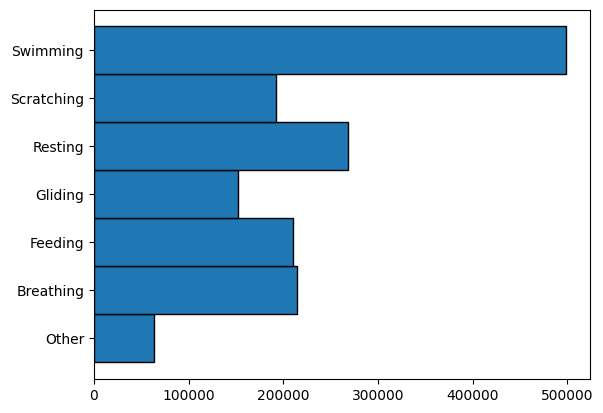

In [39]:
bins=np.arange(len(CLASSES)+1)-0.5
plt.hist(res,bins,edgecolor="k",orientation='horizontal');
xtics=range(len(CLASSES))
xtics_label=[CLASS.name for CLASS in CLASSES]
plt.yticks(xtics,xtics_label);
plt.savefig(DIR_OUT+"/sampling rep")

# Vnet with pytorch

In [ ]:
class SpatialDropout1D(nn.Module):
    def __init__(self, p: float = 0.5):
        """
        Spatial Dropout for 1D inputs (batch_size, channels, sequence_length).
        It drops entire channels (features) across all timesteps.

        Args:
            p (float): dropout probability (default=0.5)
        """
        super(SpatialDropout1D, self).__init__()
        self.dropout = nn.Dropout2d(p)

    def forward(self, x):
        # x shape: (batch_size, channels, sequence_length)
        x = x.unsqueeze(3)  # Add fake height dimension (N, C, L, 1)
        x = self.dropout(x)  # Apply Dropout2d
        return x.squeeze(3)

class VNet4Levels(nn.Module):
    def __init__(self, in_channels, out_channels, model_depth, dropout_rate=0.5, kernel_size=5):
        super(VNet4Levels, self).__init__()

        self.in_channels = in_channels
        self.out_channels=out_channels
        self.depth = model_depth
        self.dropout_rate = dropout_rate
        self.kernel_size = kernel_size

        self.dropout = SpatialDropout1D(p=dropout_rate)

        # Define layers
        self.conv1 = self.double_conv(self.in_channels, self.depth)
        self.down1 = nn.Conv1d(self.depth, self.depth * 2, kernel_size=2, stride=2, padding=0)
        self.conv2 = self.double_conv(self.depth * 2, self.depth * 2)
        
        self.down2 = nn.Conv1d(self.depth * 2, self.depth * 4, kernel_size=2, stride=2, padding=0)
        self.conv3 = self.double_conv(self.depth * 4, self.depth * 4)
        
        self.down3 = nn.Conv1d(self.depth * 4, self.depth * 8, kernel_size=2, stride=2, padding=0)
        self.conv4 = self.double_conv(self.depth * 8, self.depth * 8)
        
        self.up1 = self.make_up(self.depth * 8, self.depth * 4)
        self.conv5 = self.double_conv(self.depth * 4, self.depth * 4)
        
        self.up2 = self.make_up(self.depth * 4, self.depth * 2)
        self.conv6 = self.double_conv(self.depth * 2, self.depth * 2)
        
        self.up3 = self.make_up(self.depth * 2, self.depth)
        self.conv7 = self.double_conv(self.depth, self.depth)

        #last layer 
        self.classifier = nn.Conv1d(self.depth, self.out_channels, kernel_size=1)

    def double_conv(self, in_channels, depth):
        return nn.Sequential(
            nn.Conv1d(in_channels, depth, self.kernel_size, padding=2),
            nn.BatchNorm1d(depth),
            nn.ReLU(inplace=True),
            nn.Conv1d(depth, depth, self.kernel_size, padding=2, bias=False),
            nn.BatchNorm1d(depth ),
            nn.ReLU(inplace=True),
            #nn.Dropout(self.dropout_rate)
        )
    
    def make_up(self, in_channels, depth):
        return nn.Sequential(
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv1d(in_channels, depth, kernel_size=3, padding=1),
            nn.BatchNorm1d(depth),
            nn.ReLU(inplace=True)
        )

    
    def forward(self, x):
        conv1 = self.conv1(x)
        conv1_d=self.dropout(conv1)
        down1 = self.down1(conv1_d)
        down1= F.relu(down1)
        conv2 = self.conv2(down1)
        conv2_d=self.dropout(conv2)
        
        y = torch.add(down1 , conv2_d)
        down2 = self.down2(y)
        down2=F.relu(down2)
        conv3 = self.conv3(down2)
        conv3_d=self.dropout(conv3)
        

        y = torch.add(down2 , conv3_d)
        down3 = self.down3(y)
        down3=F.relu(down3)
        conv4 = self.conv4(down3)
        conv4_d=self.dropout(conv4)
        
        #PATCH_DIM/4
        up1 = self.up1(conv4_d)
        y = torch.add(conv3_d , up1)
        pre_conv5=self.conv5(y)
        pre_conv5_d=self.dropout(pre_conv5)
        conv5 = torch.add(pre_conv5_d , up1)
        
        #PATCH_DIM/2
        up2 = self.up2(conv5)
        y = torch.add(conv2 , up2)
        pre_conv6=self.conv6(y)
        pre_conv6_d=self.dropout(pre_conv6)
        conv6 = torch.add(pre_conv6_d , up2)
        
        #PATCH_DIM
        up3 = self.up3(conv6)
        y = torch.add(conv1 , up3)
        pre_conv7=self.conv7(y)
        pre_conv7_d=self.dropout(pre_conv7)
        conv7 = torch.add(pre_conv7_d , up3)
       

        output=self.classifier(conv7)
        softmax=F.softmax(output, dim=1)
        
        return softmax


In [ ]:
in_channels=7
out_channels=7
model_depth=32
window_size=800

model = VNet4Levels(in_channels, out_channels, model_depth, dropout_rate=0.5)

print(model)

In [43]:
#from torchsummary import summary

device = torch.device("xpu" if torch.xpu.is_available() else "cpu")
print(f"Using device: {device}")

model = VNet4Levels(in_channels, out_channels, model_depth, dropout_rate=0.5).to(device)
#summary(model, input_size=(7, 800), device=str(device))

Using device: xpu


In [44]:
ponde = torch.tensor(np.array([CLASS.loss_weight for CLASS in CLASSES], dtype=np.float32))
ponde /= torch.sum(ponde)

In [45]:
ponde

tensor([0.0123, 0.1235, 0.2469, 0.1235, 0.1235, 0.2469, 0.1235])

In [46]:
def dice_coef(y_true, y_pred, smooth=1e-8):
    intersection = torch.sum(y_true * y_pred, dim=2)
    return (2. * intersection + smooth) / (torch.sum(y_true, dim=2) + torch.sum(y_pred, dim=2) + smooth)

def dice_loss(y_true, y_pred, weight):
    weight = weight.view(1, -1).to(y_true.device)
    weighted_dice=dice_coef(y_true, y_pred)*weight
    return 1 - weighted_dice.mean()

In [47]:
"""
SMOOTH=1
def dice_loss(preds,target):
    target = target.type_as(preds)
    loss = 1 - ( 2 * ( preds * target).sum() + SMOOTH ) / ( (preds + target).sum() + SMOOTH )
    return loss
"""

'\nSMOOTH=1\ndef dice_loss(preds,target):\n    target = target.type_as(preds)\n    loss = 1 - ( 2 * ( preds * target).sum() + SMOOTH ) / ( (preds + target).sum() + SMOOTH )\n    return loss\n'

In [48]:
import time

class Trainer:
    def __init__(self, model, optimizer, criterion, batch_size, loss_weight, device):
        self.model = model
        self.optimizer = optimizer
        self.criterion = criterion
        self.batch_size=batch_size
        self.loss_weight=loss_weight
        self.device = device
        self.best_loss = float('inf')
        self.total_duration = 0
        self.durations = []
    
    def train(self, train_gene, val_gene, epochs, patience=10):
        counter = 0
        self.train_losses=[]
        self.val_losses=[]
        self.train_accuracies, self.val_accuracies = [], []
        self.best_epochs=[]

        for epoch in range(epochs):

            starting_time = time.time()

            X_ep, Y_ep = next(train_gene)
            X_val_ep, Y_val_ep = next(val_gene)

            Y_ep=F.one_hot(torch.tensor(Y_ep, dtype=torch.long), num_classes=7)
            Y_val_ep=F.one_hot(torch.tensor(Y_val_ep, dtype=torch.long), num_classes=7)

            train_loader=self._create_pytorch_dataloader(X_ep, Y_ep, shuffle=False)
            val_loader=self._create_pytorch_dataloader(X_val_ep, Y_val_ep, shuffle=False)

            self.model.train(True)
            total_loss, total_acc = 0, 0

            num_batches = len(train_loader)
            num_samples = len(train_loader.dataset)

            for x_batch, y_batch in train_loader:
                x_batch, y_batch = x_batch.to(self.device), y_batch.to(self.device)
                # Reset gradients
                self.optimizer.zero_grad()
                # Forward pass
                y_pred = self.model(x_batch)
                # Compute loss
                loss = self.criterion(y_pred, y_batch,self.loss_weight)
                # Backward and optimize
                loss.backward()
                self.optimizer.step()
                # Calculate Loss
                total_loss += loss.item()
                total_acc += self._compute_accuracy(y_pred, y_batch) 

            train_epoch_loss=total_loss/num_batches
            self.train_losses.append(train_epoch_loss)

            train_epoch_acc = total_acc / num_batches
            self.train_accuracies.append(train_epoch_acc)

            #evaluation
            val_loss, val_acc  = self._val_one_epoch(val_loader)
            self.val_losses.append(val_loss)
            self.val_accuracies.append(val_acc)

            print(f"Epoch {epoch+1}, Train Loss: {train_epoch_loss:.4f}, Train Acc: {train_epoch_acc:.4f}, "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
            
            #early_stopping
            if val_loss < self.best_loss:
                
                
                print("val_loss improved from {:.5f} to {:.5f}".format(self.best_loss, val_loss))
                self.best_loss = val_loss  
                self.best_epochs.append(epoch)  
                print("Model is saved on epoch {:d}.".format(epoch))
                
                save_path = os.path.join(Path(DIR_OUT, "model.pth"))
                torch.save(self.model.state_dict(), save_path)
                counter = 0
            else:
                counter += 1
                if counter >= patience:
                    print("Early stopping due to no improvement")
                    break

            # saving training epoch history
            duration=time.time()-starting_time
            self.durations.append(duration)
            self.total_duration+=duration

    
    def _create_pytorch_dataloader(self, X, Y, shuffle):

        X_tensor = torch.from_numpy(X).float()
        X_tensor=X_tensor.permute(0, 2, 1)
        Y_tensor=Y.permute(0, 2, 1)
        dataset = torch.utils.data.TensorDataset(X_tensor, Y_tensor)
        loader = torch.utils.data.DataLoader(
            dataset, batch_size=self.batch_size, shuffle=shuffle
        )
        return loader
    
    def _compute_accuracy(self,y_pred, y_true):

        y_pred_labels = y_pred.argmax(dim=1)  # Shape: (batch_size, seq_length)
        y_true_labels = y_true.argmax(dim=1)  # Convert one-hot to class index (batch_size, seq_length)

        correct = (y_pred_labels == y_true_labels).float()
        return correct.mean().item()  # Return scalar accuracy


    def _val_one_epoch(self, val_loader):
        self.model.train(False)

        num_batches = len( val_loader)
        num_samples = len( val_loader.dataset)
        
        with torch.no_grad():
            total_loss, total_acc = 0.0, 0.0

            for x_batch, y_batch in val_loader:
                x_batch, y_batch = x_batch.to(self.device), y_batch.to(self.device)
                #forward pass
                y_pred = self.model(x_batch)
                #compute loss
                loss = self.criterion(y_pred, y_batch, self.loss_weight)
                #compute loss
                total_loss += loss.item()
                total_acc += self._compute_accuracy(y_pred, y_batch)

        return total_loss / num_batches, total_acc / num_batches

In [49]:

model = VNet4Levels(len(DESCRIPTORS_SELEC), len(CLASSES), MODEL_DEPTH, dropout_rate=DROPOUT)


# Training setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

optimizer = optim.Adam(model.parameters(), lr=LR_initial)
criterion = dice_loss

trainer = Trainer(model, optimizer, criterion, BATCH_SIZE, ponde, device)

# Example usage (replace with actual DataLoader objects)
# trainer.train(train_loader, val_loader, epochs=30)

In [50]:
memo["nb_train_per_epoch"]=10000
train_gen=oneEpoch_generator_window(NAMES_TRAIN,size = memo["nb_train_per_epoch"])

#X,Y=next(train_gen)
#X.shape,Y.shape

In [51]:
memo["nb_val_per_epoch"]=6000
valid_gen=oneEpoch_generator_window(NAMES_VAL,size = memo["nb_val_per_epoch"])

#X_val,Y_val=next(valid_gen)
#X_val.shape,Y_val.shape

### Let's go

In [52]:
trainer.train(train_gen, valid_gen, epochs=30)

[('Other', np.float64(0.1)), ('Breathing', np.float64(0.1)), ('Feeding', np.float64(0.2)), ('Gliding', np.float64(0.3)), ('Resting', np.float64(0.05)), ('Scratching', np.float64(0.2)), ('Swimming', np.float64(0.05))]
[('Other', np.float64(0.1)), ('Breathing', np.float64(0.1)), ('Feeding', np.float64(0.2)), ('Gliding', np.float64(0.3)), ('Resting', np.float64(0.05)), ('Scratching', np.float64(0.2)), ('Swimming', np.float64(0.05))]
the class to promote:Other is not present in:CC-07-47_14-02-2018
the class to promote:Feeding is not present in:CC-07-47_14-02-2018
the class to promote:Feeding is not present in:CC-07-48_10-10-2018
the class to promote:Gliding is not present in:CC-07-47_14-02-2018
the class to promote:Resting is not present in:CC-07-47_14-02-2018
the class to promote:Scratching is not present in:CC-07-47_14-02-2018
the class to promote:Scratching is not present in:CC-07-48_10-10-2018
Epoch 1, Train Loss: 0.9867, Train Acc: 0.3463, Val Loss: 0.9847, Val Acc: 0.3750
val_loss im

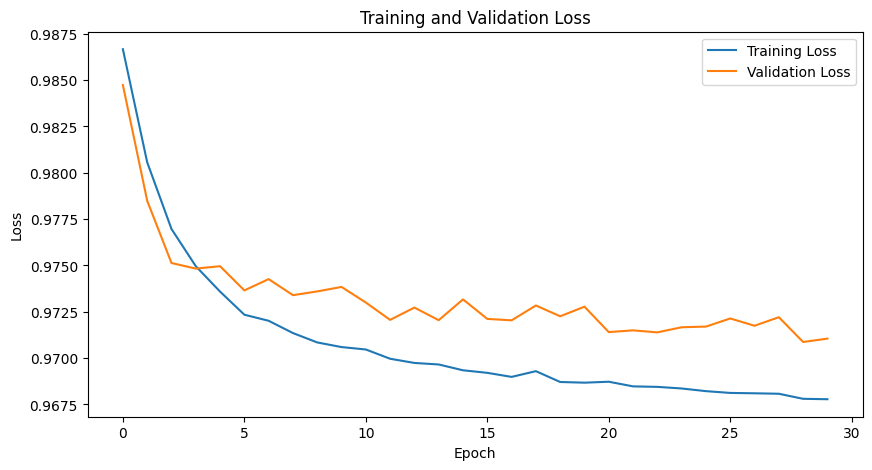

In [53]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(trainer.train_losses, label='Training Loss')
plt.plot( trainer.val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

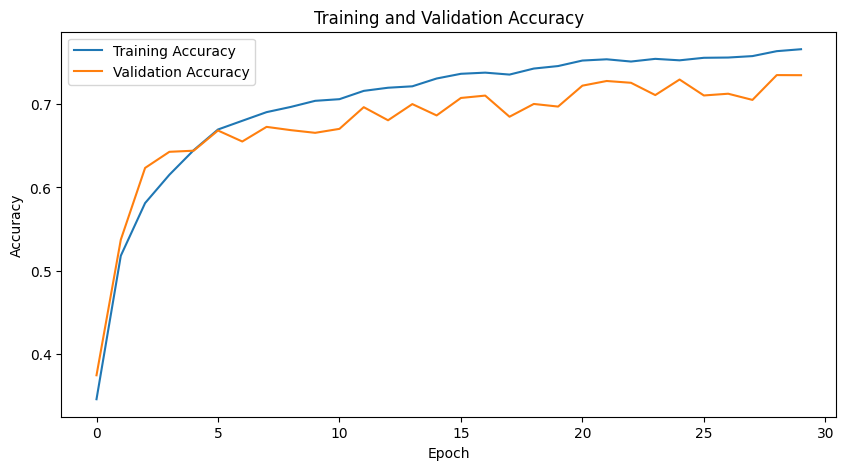

In [54]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(trainer.train_accuracies, label='Training Accuracy')
plt.plot( trainer.val_accuracies, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

In [55]:
print("Training took {:.2f} seconds".format(trainer.total_duration))
print("Which is {:.2f} minutes".format(trainer.total_duration/60))

Training took 2363.17 seconds
Which is 39.39 minutes


# Testing


In [56]:
DIR_OUT

'Model_results/modelVNET=2026_08_14_TestA_pressurecorrected'

In [57]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [58]:
model= VNet4Levels(len(DESCRIPTORS_SELEC), len(CLASSES), MODEL_DEPTH, dropout_rate=DROPOUT)
model.load_state_dict(torch.load(os.path.join(Path(DIR_OUT, "model.pth")), weights_only=True))
model.eval()

VNet4Levels(
  (dropout): SpatialDropout1D(
    (dropout): Dropout2d(p=0.5, inplace=False)
  )
  (conv1): Sequential(
    (0): Conv1d(7, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
    (4): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (down1): Conv1d(32, 64, kernel_size=(2,), stride=(2,))
  (conv2): Sequential(
    (0): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(i

In [59]:
def cut_full_slice(matrix,label):

    margin=int(0.1*WINDOW_SIZE)
    stride=WINDOW_SIZE-2*margin

    size=len(matrix)//stride-1
    nb_input=matrix.shape[1]

    X= np.empty([size,WINDOW_SIZE,nb_input])
    Y= np.empty([size,WINDOW_SIZE],dtype=int)

    for i in range(size):
        t=i*stride
        X[i,:,:]=matrix[t:t+WINDOW_SIZE ,:]
        Y[i]=label[t:t+WINDOW_SIZE]

    return X, Y

def stick(Y):

    window_size=Y.shape[1]
    margin=int(0.1*window_size)

    res=[]
    res.append(Y[0,:window_size-margin])

    for i in range(1,len(Y)):
        res.append(Y[i,margin:-margin])

    return np.concatenate(res,axis=0)

def save_predictions(turtle_names, device, save=True):

    for i,name in enumerate(turtle_names):
        matrix=matrices[name]
        label=labels[name]
        print(name,matrix.shape,label.shape)

        X_cut,Y_cut=cut_full_slice(matrix,label)
        Y_true=stick(Y_cut)

        X_cut_tensor = torch.tensor(X_cut, dtype=torch.float32, device=device)
        X_cut_tensor=X_cut_tensor.permute(0, 2, 1).to(device)

        #prediction
        model.to(device)
        with torch.no_grad():
            Y_cut_pred_proba=model(X_cut_tensor)
            Y_cut_pred_proba = Y_cut_pred_proba.cpu().numpy().transpose(0, 2, 1)
            Y_cut_pred = np.argmax(Y_cut_pred_proba, axis=2)

        Y_pred=stick(Y_cut_pred)
        Y_pred_proba=stick(Y_cut_pred_proba)

        print(name,matrix.shape,label.shape,Y_pred.shape)

        np.save(DIR_OUT+"/"+name+"=Y_pred",Y_pred)
        np.save(DIR_OUT+"/"+name+"=Y_pred_proba",Y_pred_proba)
        np.save(DIR_OUT+"/"+name+"=Y_true",Y_true)

In [60]:
#Apply the Vnet on all files and save the predictions
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#save_predictions(NAMES_ALL, device)

#save the memo and the parameters of the model



## PLot / Comparaison

In [61]:
def get_all_1(tortle_names, device):

    all_pred={}
    all_true={}

    for i,name in enumerate(tortle_names):
        matrix=matrices[name]
        label=labels[name]
        print(name,matrix.shape,label.shape)

        X_cut,Y_cut=cut_full_slice(matrix,label)
        Y_stick=stick(Y_cut)
        all_true[name]=Y_stick

        X_cut_tensor = torch.tensor(X_cut, dtype=torch.float32, device=device)
        X_cut_tensor=X_cut_tensor.permute(0, 2, 1).to(device)

        #prediction
        model.to(device)
        with torch.no_grad():
            Y_cut_pred_proba=model(X_cut_tensor)
            Y_cut_pred_proba = Y_cut_pred_proba.cpu().numpy().transpose(0, 2, 1)
            Y_cut_pred = np.argmax(Y_cut_pred_proba, axis=2)


        Y_stick_pred=stick(Y_cut_pred)
        all_pred[name]=Y_stick_pred

    return all_pred,all_true

In [62]:
all_pred,all_true=get_all_1(NAMES_ALL, device)

CC-07-48_18-02-2019 (559219, 7) (559219,)
CC-07-48_06-10-2018 (475183, 7) (475183,)
CC-07-48_04-10-2018 (284021, 7) (284021,)
CC-07-115_13-05-2019 (731266, 7) (731266,)
CC-07-115_14-05-2019 (325009, 7) (325009,)
CC-07-48_08-04-2019_1 (157315, 7) (157315,)
CC-07-48_08-04-2019_2 (88800, 7) (88800,)
CC-07-48_08-04-2019_3 (142801, 7) (142801,)
CC-07-48_22-05-2018 (286161, 7) (286161,)
CC-07-108_11-02-2019 (160292, 7) (160292,)
CC-07-59_20-05-2018 (423855, 7) (423855,)
CC-07-47_14-02-2018 (105362, 7) (105362,)
CC-07-48_10-10-2018 (69239, 7) (69239,)
CC-07-48_08-10-2018 (535201, 7) (535201,)
CC-07-48_26-05-2018 (267301, 7) (267301,)
CC-07-107_11-02-2019 (346142, 7) (346142,)


In [63]:
def plot_categorical_vector(ax,vector,cat_selected,cat_names,markersize=2,color=None,label=None):

    #listes des couleurs par défaut
    #colors=plt.rcParams['axes.prop_cycle'].by_key()['color']

    for cat in cat_selected:
        ax.set_label("toto")
        here=(vector==cat)
        x_here=np.arange(len(vector))[here]
        y_here=cat*np.ones(len(vector))[here]
        line,=ax.plot(x_here, y_here,'o',markersize=markersize,color=color)


    line.set_label(label)

    ax.set_yticks(range(len(cat_selected)))
    ax.tick_params(colors='coral')
    labels=[]
    for cat in cat_selected:
        labels.append(str(cat)+":"+cat_names[cat])

    ax.set_yticklabels(labels)

In [64]:
def plot_compa_Y(ax,y,y_pred):

    nb_output=len(CLASSES)
    class_names=[CLASS.name for CLASS in CLASSES]


    plot_categorical_vector(ax,y,range(nb_output),class_names,markersize=3,color="blue",label="Y")
    plot_categorical_vector(ax,y_pred,range(nb_output),class_names,markersize=1,color="red",label="Y_pred")

    ax.legend()


In [65]:
def plot_compa(turtle_names,title,deb=0,fin=-1):
    #deb=0
    #fin=-1
    nb=len(turtle_names)
    fig,axs=plt.subplots(nb,1,figsize=(12,2*nb),sharex=False)
    if nb==1:axs=[axs]

    for i,name in enumerate(turtle_names):
        plot_compa_Y(axs[i],all_true[name][deb:fin],all_pred[name][deb:fin])
        axs[i].set_title(name, color="coral", fontsize=16)

    fig.tight_layout()

    fig.savefig(DIR_OUT+"/"+title+".png")

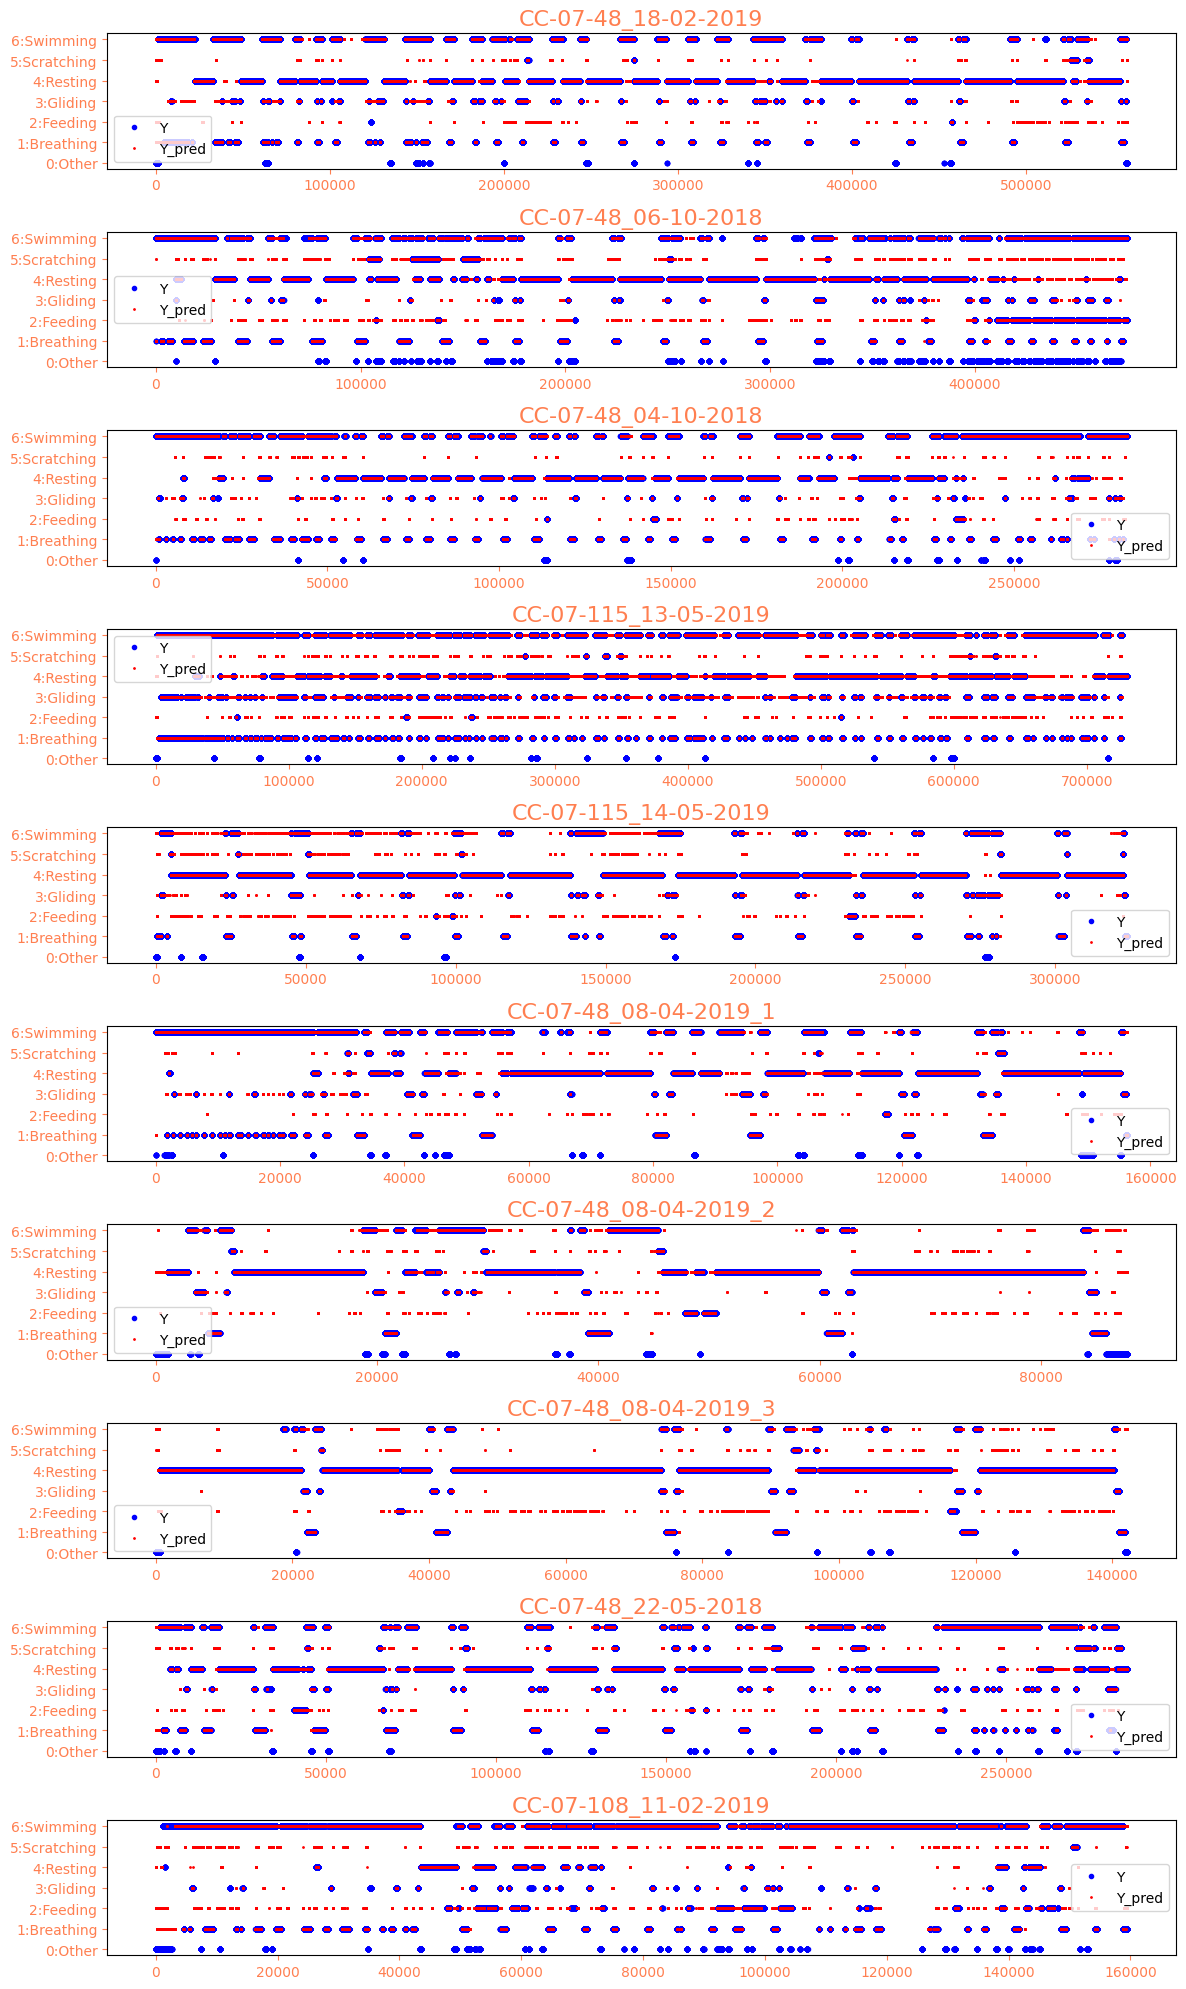

In [66]:
plot_compa(NAMES_TRAIN,"compa on train")

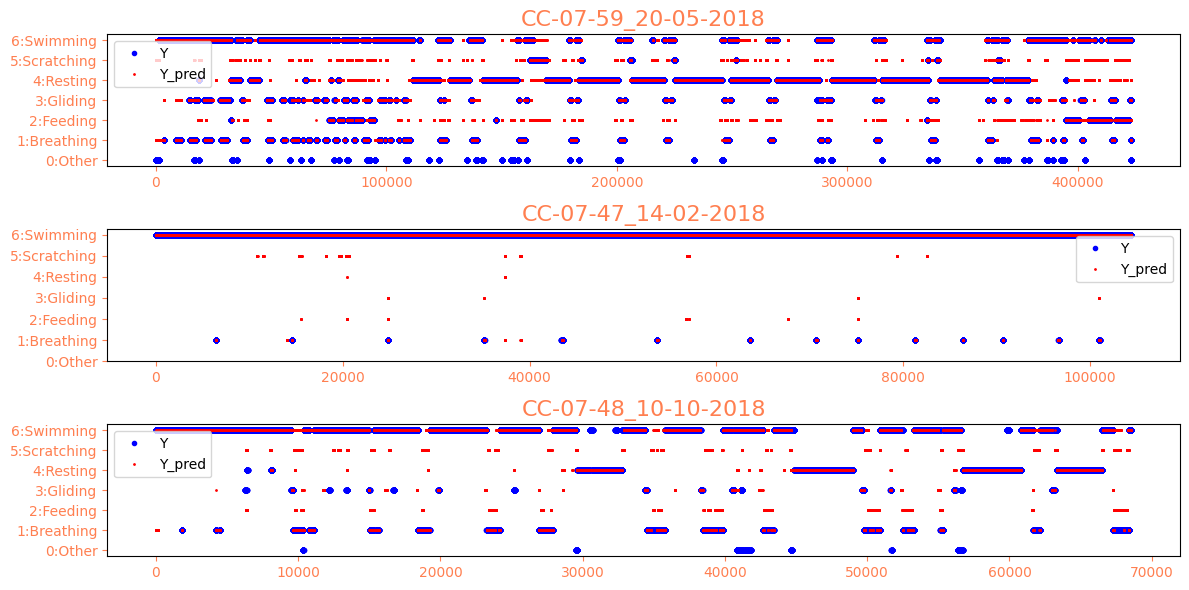

In [67]:
plot_compa(NAMES_VAL,"compa on val")

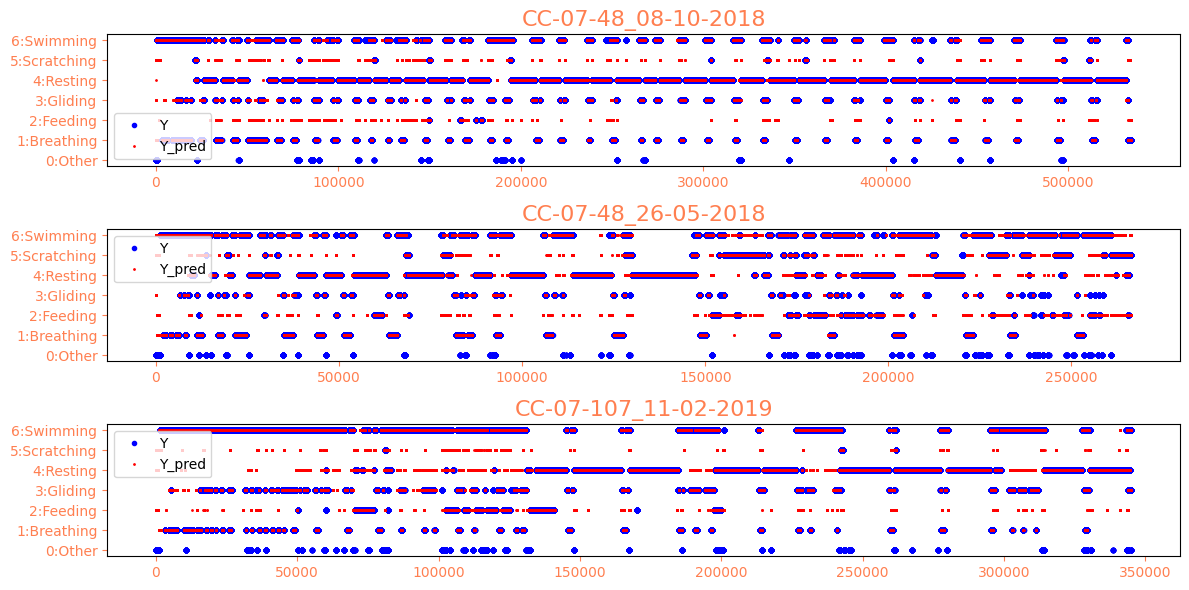

In [68]:
plot_compa(NAMES_TEST,"compa on test")

## Confusion Matrix


In [69]:
from sklearn.metrics import confusion_matrix
from sklearn.utils.multiclass import unique_labels


In [70]:
import sklearn

In [71]:
sklearn.__version__


'1.6.1'

In [72]:
from sklearn.metrics import confusion_matrix
from sklearn.utils.multiclass import unique_labels

def plot_confusion_matrix(y_true, y_pred, classes,
                          normalize, axe,
                          title,
                          cmap="jet",
                          precision=2,
                         ):


    y_true=y_true.astype(int)
    y_pred=y_pred.astype(int)

    np.set_printoptions(precision=precision)


    # Compute confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    # Only use the labels that appear in the data
    classes = classes[unique_labels(y_true, y_pred)]
    print("Confusion matrix, without normalization:")
    print(cm)

    if normalize:
        if axe=="col" :
            cm = cm.astype('float') / cm.sum(axis=0)[np.newaxis, :]
        elif axe=="row":
            cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
            print("Normalized confusion matrix")
            print(cm)


    fig, ax = plt.subplots(figsize=(12,12))
    ax.grid(False)
    im = ax.imshow(cm, interpolation='nearest', cmap=cmap)
    ax.figure.colorbar(im, ax=ax)
    # We want to show all ticks...
    ax.set(xticks=np.arange(cm.shape[1]),
           yticks=np.arange(cm.shape[0]),
           # ... and label them with the respective list entries
           xticklabels=classes, yticklabels=classes,
           ylabel='True label',
           xlabel='Predicted label')

    # Rotate the tick labels and set their alignment.
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right",
             rotation_mode="anchor")

    # Loop over data dimensions and create text annotations.
    fmt = '.'+str(precision)+'f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], fmt),
                    ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "coral")
    fig.tight_layout()
    fig.savefig(DIR_OUT+"/"+title)



Confusion matrix, without normalization:
[[     0   1114   3037    550   3013   4131   5027]
 [     0  88724   7019   1389    158   3263  10093]
 [     0      0  25070    110   3345   2811   1452]
 [     0    685    625  39292   4710    338   9911]
 [     0      0   5122     36 585838   2346    653]
 [     0      2   6231      0   2052  23062   4017]
 [     0   1996   6720   6702  17516  11536 256144]]
Normalized confusion matrix
[[0.   0.07 0.18 0.03 0.18 0.24 0.3 ]
 [0.   0.8  0.06 0.01 0.   0.03 0.09]
 [0.   0.   0.76 0.   0.1  0.09 0.04]
 [0.   0.01 0.01 0.71 0.08 0.01 0.18]
 [0.   0.   0.01 0.   0.99 0.   0.  ]
 [0.   0.   0.18 0.   0.06 0.65 0.11]
 [0.   0.01 0.02 0.02 0.06 0.04 0.85]]


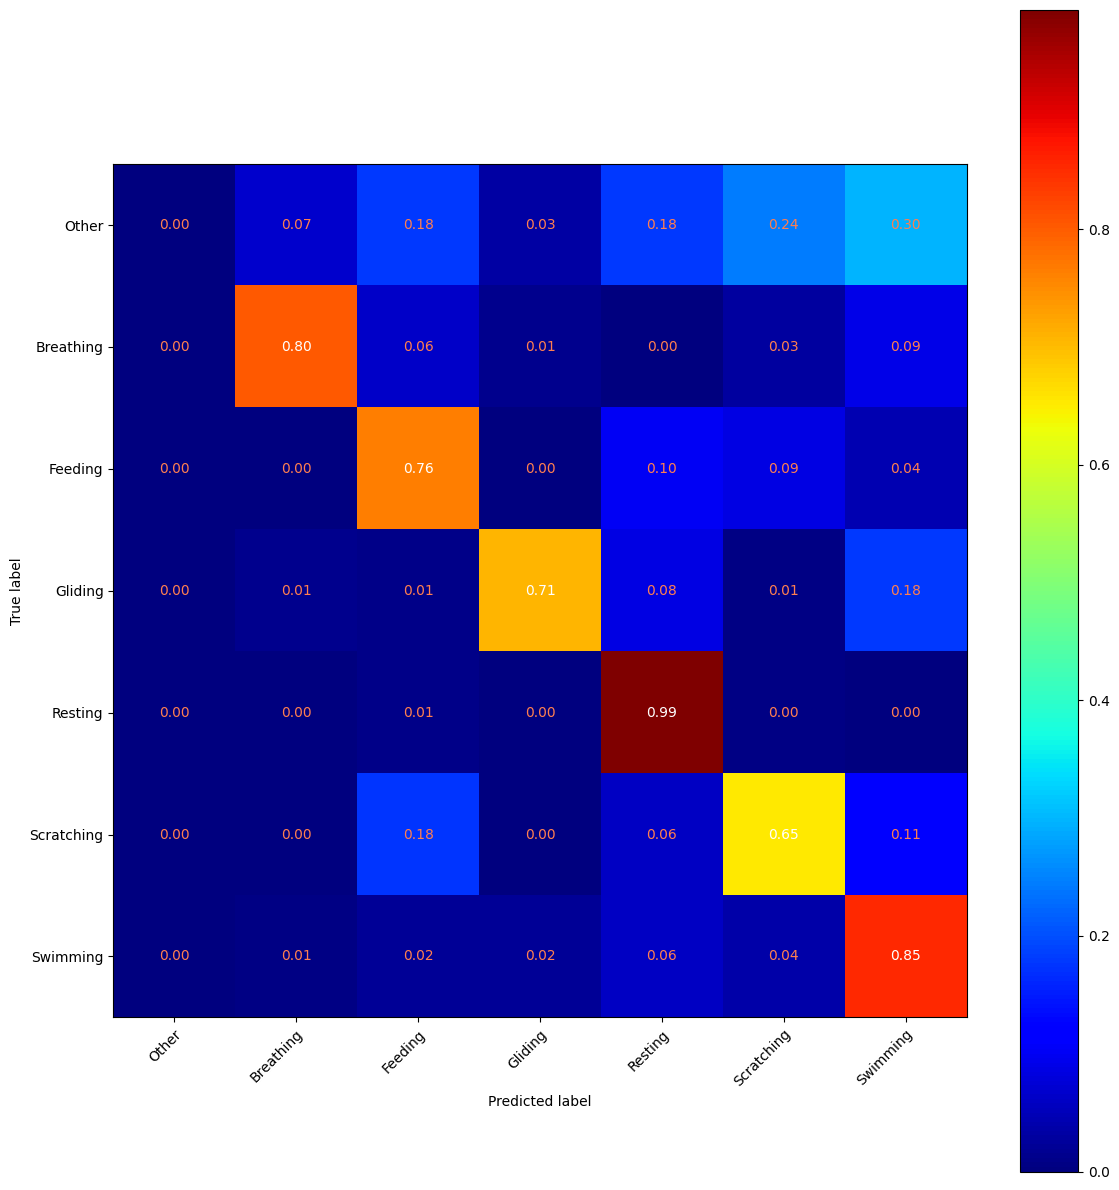

In [73]:
whole_true=[]
whole_pred=[]
for name in NAMES_TEST:
    whole_true.append(all_true[name])
    whole_pred.append(all_pred[name])

whole_true=np.concatenate(whole_true)
whole_pred=np.concatenate(whole_pred)
class_names=[CLASS.name for CLASS in CLASSES]

plot_confusion_matrix(whole_true,whole_pred, np.array(class_names),True,"row", "Confusion matrix on testing dataset")


Confusion matrix, without normalization:
[[     0   1114   3037    550   3013   4131   5027]
 [     0  88724   7019   1389    158   3263  10093]
 [     0      0  25070    110   3345   2811   1452]
 [     0    685    625  39292   4710    338   9911]
 [     0      0   5122     36 585838   2346    653]
 [     0      2   6231      0   2052  23062   4017]
 [     0   1996   6720   6702  17516  11536 256144]]


C:\Users\Bea Loubser\AppData\Local\Temp\ipykernel_32868\143899263.py:28: RuntimeWarning: invalid value encountered in divide
  cm = cm.astype('float') / cm.sum(axis=0)[np.newaxis, :]


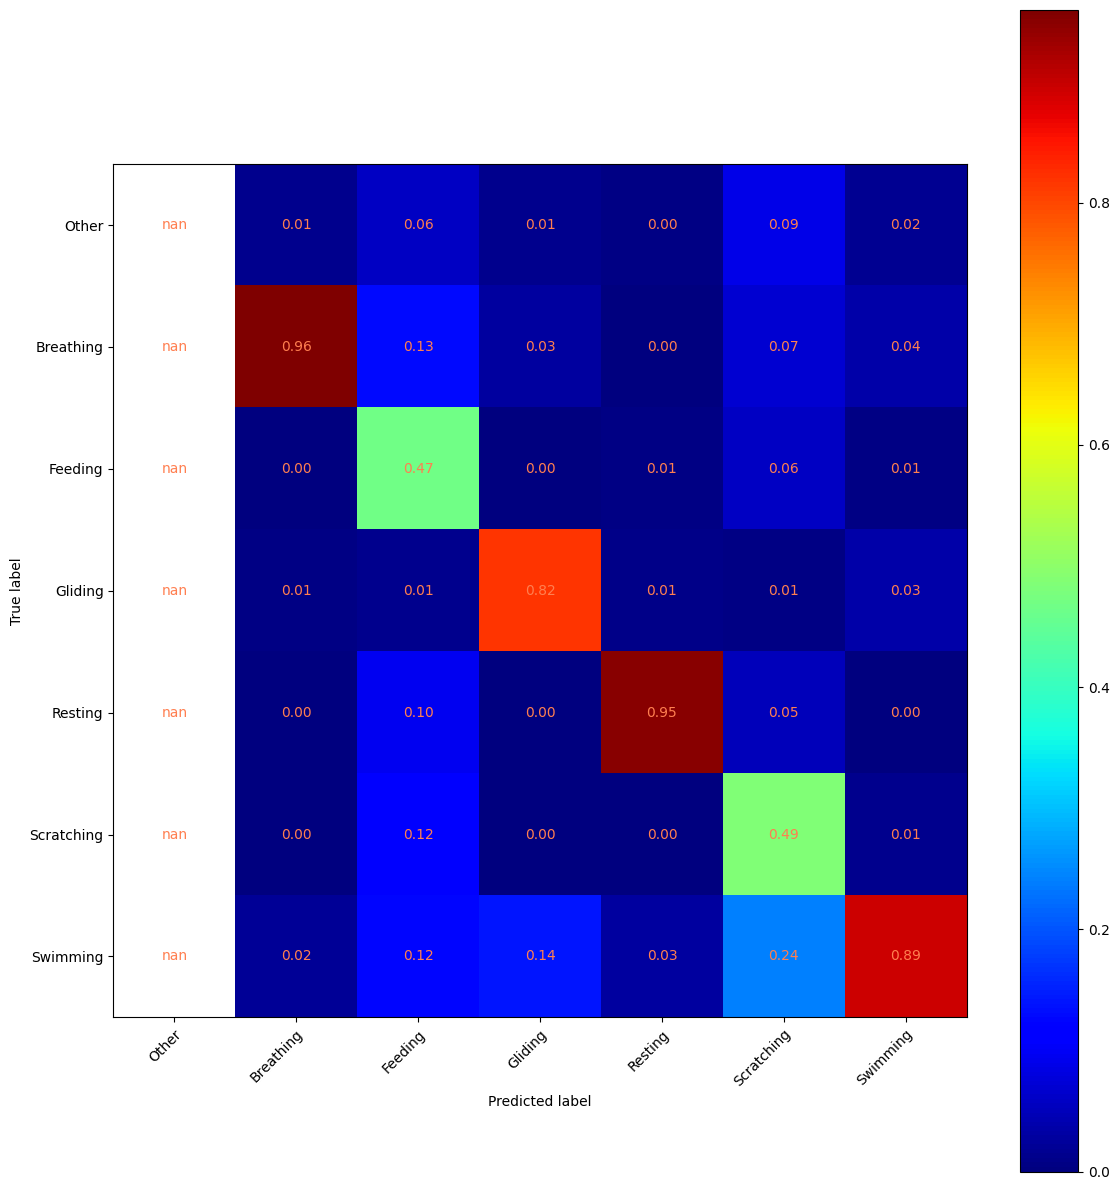

In [74]:
plot_confusion_matrix(whole_true,whole_pred, np.array(class_names),True,"col", "Confusion matrix on testing dataset")

In [75]:
#To calculate the index of Precisionm Recall, Specificity

cm = confusion_matrix(whole_true, whole_pred)

print(cm)
TP=np.diag(cm)
FP=np.sum(cm,axis=1)-TP
FN=np.sum(cm,axis=0)-TP
TN=np.ones(len(class_names))*np.sum(cm)-TP-FP-FN

Accuracy=(TP+TN)/(TP+TN+FP+FN)
Recall=TP/(TP+FN)
Precision =TP/(TP+FP)
Specificity =TN/(TN+FP)





[[     0   1114   3037    550   3013   4131   5027]
 [     0  88724   7019   1389    158   3263  10093]
 [     0      0  25070    110   3345   2811   1452]
 [     0    685    625  39292   4710    338   9911]
 [     0      0   5122     36 585838   2346    653]
 [     0      2   6231      0   2052  23062   4017]
 [     0   1996   6720   6702  17516  11536 256144]]


C:\Users\Bea Loubser\AppData\Local\Temp\ipykernel_32868\1127322538.py:12: RuntimeWarning: invalid value encountered in divide
  Recall=TP/(TP+FN)


In [76]:
df = pd.DataFrame({'Accuracy': Accuracy, 'Recall': Recall, 'Precision': Precision, 'Specificity': Specificity},
                      index = class_names)
df

,Accuracy,Recall,Precision,Specificity
Other,0.985275,NaN,0.000000,0.985275
Breathing,0.977554,0.958961,0.801873,0.979188
Feeding,0.968170,0.465777,0.764609,0.992932
Gliding,0.978133,0.817238,0.707187,0.985180
Resting,0.966007,0.950061,0.986268,0.984586
Scratching,0.967948,0.485649,0.652132,0.988800
Swimming,0.934002,0.891565,0.852069,0.948203


In [77]:
Global_accuracy=(np.sum(TP)+np.sum(TN))/(np.sum(TP)+np.sum(TN)+np.sum(FP)+np.sum(FN))
print("Global Accuracy :", Global_accuracy)

Global Accuracy : 0.9681556138478571


In [78]:
df.loc[:,'F1_score']=np.nan
for index, row in df.iterrows():
    df.loc[index,'F1_score']=2*(row['Recall']*row['Precision'])/ (row['Recall']+row['Precision'])


In [79]:
df

,Accuracy,Recall,Precision,Specificity,F1_score
Other,0.985275,NaN,0.000000,0.985275,NaN
Breathing,0.977554,0.958961,0.801873,0.979188,0.873410
Feeding,0.968170,0.465777,0.764609,0.992932,0.578904
Gliding,0.978133,0.817238,0.707187,0.985180,0.758240
Resting,0.966007,0.950061,0.986268,0.984586,0.967826
Scratching,0.967948,0.485649,0.652132,0.988800,0.556710
Swimming,0.934002,0.891565,0.852069,0.948203,0.871370


In [80]:
F1_score=np.mean(df['F1_score'][~np.isnan(df['F1_score'])])
print("F1-score :", F1_score)

F1-score : 0.7677432042753932
